# Lesson 14: PCA and neural-network regression on Boston housing

Compare a neural network trained on standardized features with the same architecture trained on principal components. Run from this folder with NumPy, pandas, Matplotlib, scikit-learn, and TensorFlow.

**Data:** [Boston Housing](https://www.kaggle.com/datasets/vikrishnan/boston-house-prices). Download `housing.csv` and place it in this lesson folder.

In [1]:
import os
os.environ["TF_NUM_INTRAOP_THREADS"] = "1"
os.environ["TF_NUM_INTEROP_THREADS"] = "1"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

tf.keras.utils.set_random_seed(42)
columns = ["CRIM", "ZN", "INDUS", "CHAS", "NOX", "RM", "AGE", "DIS", "RAD", "TAX", "PTRATIO", "B", "LSTAT", "MEDV"]
df = pd.read_csv("housing.csv", sep=r"\s+", names=columns)
X, y = df.drop(columns=["MEDV", "B"]), df[["MEDV"]]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42)
x_scaler = StandardScaler().fit(X_train)
y_scaler = StandardScaler().fit(y_train)
train_x, val_x, test_x = (x_scaler.transform(v) for v in (X_train, X_val, X_test))
train_y, val_y = y_scaler.transform(y_train), y_scaler.transform(y_val)

## PCA

Fit the scaler and PCA on training rows, then transform the validation and test sets with those fitted parameters. Keep enough components to explain at least 95% of the training variance.

Features: 12; retained components: 9


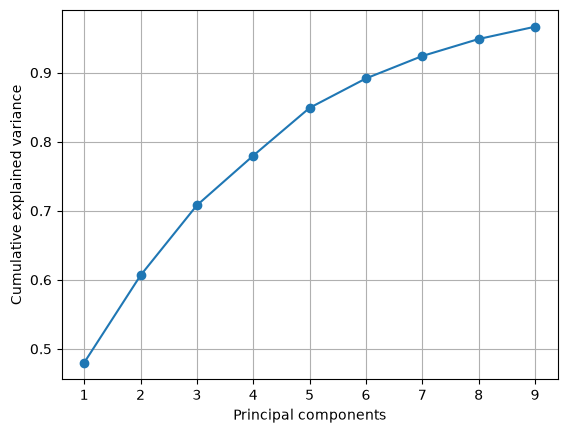

In [2]:
pca = PCA(n_components=0.95).fit(train_x)
train_pca, val_pca, test_pca = (pca.transform(v) for v in (train_x, val_x, test_x))
print(f"Features: {X.shape[1]}; retained components: {pca.n_components_}")
plt.plot(np.arange(1, pca.n_components_ + 1),
         np.cumsum(pca.explained_variance_ratio_), marker="o")
plt.xlabel("Principal components")
plt.ylabel("Cumulative explained variance")
plt.grid()
plt.show()

## Train and compare

Both models use the same architecture, training rows, and validation split. The test set is evaluated once per model. MAE and RMSE use the original target units.

In [3]:
def fit_model(train, validation):
    tf.keras.utils.set_random_seed(42)
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(train.shape[1],)),
        tf.keras.layers.Dense(32, activation="relu"),
        tf.keras.layers.Dense(16, activation="relu"),
        tf.keras.layers.Dense(1),
    ])
    model.compile(optimizer="adam", loss="mse")
    history = model.fit(train, train_y, validation_data=(validation, val_y),
                        epochs=40, batch_size=64, verbose=0)
    return model, history

model_full, history_full = fit_model(train_x, val_x)
model_pca, history_pca = fit_model(train_pca, val_pca)

W0000 00:00:1793920308.452437  453870 cpu_utils.cc:145] Failed to get CPU frequency: 0 Hz
W0000 00:00:1793920308.482351  453870 op_level_cost_estimator.cc:743] Invalid device specifications for CPU: goo.gle/debugproto   type: "CPU" model: "0" num_cores: 8 environment { key: "cpu_instruction_set" value: "ARM NEON" } environment { key: "eigen" value: "3.5.0" } l1_cache_size: 16384 l2_cache_size: 524288 l3_cache_size: 524288 memory_size: 268435456


W0000 00:00:1793920309.814266  453870 op_level_cost_estimator.cc:743] Invalid device specifications for CPU: goo.gle/debugproto   type: "CPU" model: "0" num_cores: 8 environment { key: "cpu_instruction_set" value: "ARM NEON" } environment { key: "eigen" value: "3.5.0" } l1_cache_size: 16384 l2_cache_size: 524288 l3_cache_size: 524288 memory_size: 268435456


W0000 00:00:1793920310.641771  453870 op_level_cost_estimator.cc:743] Invalid device specifications for CPU: goo.gle/debugproto   type: "CPU" model: "0" num_cores: 8 environment { key: "cpu_instruction_set" value: "ARM NEON" } environment { key: "eigen" value: "3.5.0" } l1_cache_size: 16384 l2_cache_size: 524288 l3_cache_size: 524288 memory_size: 268435456


W0000 00:00:1793920311.998241  453870 op_level_cost_estimator.cc:743] Invalid device specifications for CPU: goo.gle/debugproto   type: "CPU" model: "0" num_cores: 8 environment { key: "cpu_instruction_set" value: "ARM NEON" } environment { key: "eigen" value: "3.5.0" } l1_cache_size: 16384 l2_cache_size: 524288 l3_cache_size: 524288 memory_size: 268435456


W0000 00:00:1793920312.905932  453870 op_level_cost_estimator.cc:743] Invalid device specifications for CPU: goo.gle/debugproto   type: "CPU" model: "0" num_cores: 8 environment { key: "cpu_instruction_set" value: "ARM NEON" } environment { key: "eigen" value: "3.5.0" } l1_cache_size: 16384 l2_cache_size: 524288 l3_cache_size: 524288 memory_size: 268435456


W0000 00:00:1793920313.666303  453870 op_level_cost_estimator.cc:743] Invalid device specifications for CPU: goo.gle/debugproto   type: "CPU" model: "0" num_cores: 8 environment { key: "cpu_instruction_set" value: "ARM NEON" } environment { key: "eigen" value: "3.5.0" } l1_cache_size: 16384 l2_cache_size: 524288 l3_cache_size: 524288 memory_size: 268435456


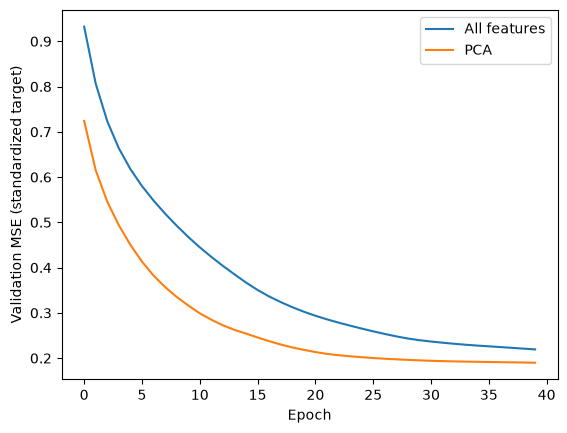

In [4]:
for label, history in [("All features", history_full), ("PCA", history_pca)]:
    plt.plot(history.history["val_loss"], label=label)
plt.xlabel("Epoch")
plt.ylabel("Validation MSE (standardized target)")
plt.legend()
plt.show()

In [5]:
predictions = {
    "All features": y_scaler.inverse_transform(model_full.predict(test_x, verbose=0)).ravel(),
    "PCA": y_scaler.inverse_transform(model_pca.predict(test_pca, verbose=0)).ravel(),
}
pd.DataFrame({
    name: {"MAE": mean_absolute_error(y_test, pred),
           "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
           "R²": r2_score(y_test, pred)}
    for name, pred in predictions.items()
}).T.round(5)

,MAE,RMSE,R²
All features,2.71773,4.43635,0.73162
PCA,2.44889,3.90855,0.79168


## Small hyperparameter search

Compare two hidden-layer widths and two learning rates using the PCA training and validation sets. This short search is illustrative: it is not cross-validation, and its results do not use the test set.

In [6]:
search_results = []
for units in (16, 32):
    for learning_rate in (0.001, 0.01):
        tf.keras.utils.set_random_seed(42)
        candidate = tf.keras.Sequential([
            tf.keras.layers.Input(shape=(train_pca.shape[1],)),
            tf.keras.layers.Dense(units, activation="relu"),
            tf.keras.layers.Dense(1),
        ])
        candidate.compile(optimizer=tf.keras.optimizers.Adam(learning_rate), loss="mse")
        candidate.fit(train_pca, train_y, epochs=10, batch_size=128, verbose=0)
        val_mse = candidate.evaluate(val_pca, val_y, verbose=0)
        search_results.append({"units": units, "learning_rate": learning_rate,
                               "validation_mse_standardized": val_mse})
pd.DataFrame(search_results).sort_values("validation_mse_standardized").reset_index(drop=True)

W0000 00:00:1793920315.007719  453870 op_level_cost_estimator.cc:743] Invalid device specifications for CPU: goo.gle/debugproto   type: "CPU" model: "0" num_cores: 8 environment { key: "cpu_instruction_set" value: "ARM NEON" } environment { key: "eigen" value: "3.5.0" } l1_cache_size: 16384 l2_cache_size: 524288 l3_cache_size: 524288 memory_size: 268435456


W0000 00:00:1793920316.750825  453870 op_level_cost_estimator.cc:743] Invalid device specifications for CPU: goo.gle/debugproto   type: "CPU" model: "0" num_cores: 8 environment { key: "cpu_instruction_set" value: "ARM NEON" } environment { key: "eigen" value: "3.5.0" } l1_cache_size: 16384 l2_cache_size: 524288 l3_cache_size: 524288 memory_size: 268435456


W0000 00:00:1793920317.930967  453870 op_level_cost_estimator.cc:743] Invalid device specifications for CPU: goo.gle/debugproto   type: "CPU" model: "0" num_cores: 8 environment { key: "cpu_instruction_set" value: "ARM NEON" } environment { key: "eigen" value: "3.5.0" } l1_cache_size: 16384 l2_cache_size: 524288 l3_cache_size: 524288 memory_size: 268435456


,units,learning_rate,validation_mse_standardized
0,32,0.010,0.212047
1,16,0.010,0.225003
2,32,0.001,0.581976
3,16,0.001,1.019197
